# LSTM

Обычная RNN имела множество проблем, в том числе, в ней очень быстро затухала информация о предыдущих словах в предложении. Помимо этого, были проблемы с затуханием/взрывом самого градиента. 

Эти проблемы были частично решены в LSTM, предложенной в [Hochreiter & Schmidhuber (1997)](http://www.bioinf.jku.at/publications/older/2604.pdf)

В обычной RNN в ячейке был только один путь передачи информации. На каждом шаге происходит сливание информации, которая была накоплена с предыдущих шагов, с текущей:


<img src = "https://edunet.kea.su/repo/EduNet-content/L08/out/simple_rnn_h_state.png" width="700px">


При этом информация о предыдущих токенах очень быстро затухает и теряется общая информация о предложении.

Структура ячейки LSTM намного сложнее. Здесь есть целых 4 линейных слоя, каждый из которых выполняет разные задачи.

<img src="https://edunet.kea.su/repo/EduNet-content/L08/out/lstm_chain.png" width="700px">

<img src="https://edunet.kea.su/repo/EduNet-content/L08/out/lstm_chain_notation.png" width="700px">

Главное нововведение - в LSTM был добавлен путь $c$, который по задумке должен этот общий контекст сохранять. 

<img src="https://edunet.kea.su/repo/EduNet-content/L08/out/lstm_c_state_highway.png" width="300px">

Другими словами, путь $c$ (иногда называется highway, магистраль)  помогает нейронной сети сохранять важную информацию, встретившуюся в какой-то момент в предложении, все время, пока эта информация требуются. 

### LSTMCell

[pytorch LSTMCELL](https://pytorch.org/docs/stable/generated/torch.nn.LSTMCell.html)

Интерфейс отличается от RNNCell количеством входов и выходов

In [1]:
import torch

lstm_cell = torch.nn.LSTMCell(input_size=3, hidden_size=4)
input = torch.randn(1, 3) # batch, input_size
h_0 = torch.randn(1, 4)
c_0 = torch.randn(1, 4)
h, c = lstm_cell(input, (h_0, c_0)) # second arg is tuple
print("Shape of h:", h.shape) # batch, hidden_size
print("Shape of c:", c.shape) # batch, hidden_size

Shape of h: torch.Size([1, 4])
Shape of c: torch.Size([1, 4])


### LSTM in Pytorch

Отличие от RNN состоит в том, что кроме $h$ возвращается еще и $c$. 

In [2]:
import torch.nn as nn

lstm = nn.LSTM(input_size=4, hidden_size=5)
input = torch.randn(3, 2, 4) # seq_len, batch, input_size
out, (h, c) = lstm(input) # h and c returned in tuple

print("Input shape:".ljust(15), input.shape)
print("Shape of h".ljust(15), h.shape) # batch, hidden_size
print("Shape of c".ljust(15), c.shape) # batch, hidden_size
print("Output shape:".ljust(15), out.shape) # seq_len, batch, hidden_size : h for each element

Input shape:    torch.Size([3, 2, 4])
Shape of h      torch.Size([1, 2, 5])
Shape of c      torch.Size([1, 2, 5])
Output shape:   torch.Size([3, 2, 5])


### Пример использования на задаче с временным рядом

Чтобы убедиться в работоспособности конструкции, заменим RNN блок на LSTM в задаче предсказания временного ряда.

In [3]:
import pandas as pd
dataset = pd.read_csv('https://edunet.kea.su/repo/EduNet-web_dependencies/L08/airline-passengers.csv')
dataset.head()

,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [4]:
# Min - Max normalization
training_data = dataset.iloc[:, 1:2].values
td_min = training_data.min()
td_max = training_data.max()
print('Initial statistics:')
print('Minimum value:', repr(td_min).rjust(5))
print('Maximum value:', repr(td_max).rjust(5))

training_data = (training_data - td_min) / (td_max - td_min)
print('\nResulting statistics:')
print('Minimum value:', repr(training_data.min()).rjust(5))
print('Maximum value:', repr(training_data.max()).rjust(5))

Initial statistics:
Minimum value:   104
Maximum value:   622

Resulting statistics:
Minimum value:   0.0
Maximum value:   1.0


In [5]:
import numpy as np

# create data "ensemble"
def sliding_windows(data, seq_length):
    x = []
    y = []

    for i in range(len(data) - seq_length):
        _x = data[i:(i + seq_length)] # выбор нескольких последовательных наблюдений
        _y = data[i + seq_length] # выбор последующего наблюдения
        x.append(_x)
        y.append(_y)

    return torch.Tensor(np.array(x)), torch.Tensor(np.array(y))
    
# установливаем длину ансамбля; точность прогнозов и 
# скоростные характеристики, которые почти всегда зависят от ее размера
seq_length = 8 # можно поменять на 2 и 32 и посомтреть, что получится
x, y = sliding_windows(training_data, seq_length)

train_size = int(len(y) * 0.8)

x_train = x[:train_size]
y_train = y[:train_size]

x_test = x[train_size:]
y_test = y[train_size:]

print("Train data:")
print("x shape:", x_train.shape)
print("y shape:", y_train.shape)

print("\nTest data:")
print("x shape:", x_test.shape)
print("y shape:", y_test.shape)

Train data:
x shape: torch.Size([108, 8, 1])
y shape: torch.Size([108, 1])

Test data:
x shape: torch.Size([28, 8, 1])
y shape: torch.Size([28, 1])


In [6]:
def time_series_plot(train_predict):
  data_predict = train_predict.data
  y_data_plot = y.data

  # Денормализация
  data_predict = data_predict[0] * (td_max - td_min) + td_min
  y_data_plot = y_data_plot * (td_max - td_min) + td_min 

  # Ploitting
  plt.figure(figsize=(12, 4))
  plt.axvline(x=train_size, c='r', linestyle='--')
  # смещение кривой, так как первое значение y не соответствует первому значению в целом
  plt.plot(seq_length + np.arange(y_data_plot.shape[0]), y_data_plot)
  plt.plot(seq_length + np.arange(y_data_plot.shape[0]), data_predict)
  
  plt.title("Number of passengers per month")
  plt.ylabel("#passengers")
  plt.xlabel("Month")
  plt.xticks(labels_to_display, dataset['Month'][labels_to_display])
  
  plt.legend(['Train/Test separation', 'Real', 'Predicted'])
  plt.grid(axis='x')
  plt.show()

In [7]:
# Определяем новую модель на основе LSTM

class LSTMAirTrafficPredictor(nn.Module):

    def __init__(self, input_size, hidden_size):
        # hidden_size == number of neurons 
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1) # Прогнозируем только одно значение

    def forward(self, x):
        out, (h, c) = self.lstm(x) 
        y = self.fc(h)
        return y

lstm =  LSTMAirTrafficPredictor(input_size=1, hidden_size=4)
input = torch.randn((108, 8, 1)) 
out = lstm(input)

print("LSTM model we use consider first input dimension as a batch dimension, output dimension logic has not changed:")
print("Input shape:".ljust(15), input.shape)
print("Output shape:".ljust(15), out.shape)

LSTM model we use consider first input dimension as a batch dimension, output dimension logic has not changed:
Input shape:    torch.Size([108, 8, 1])
Output shape:   torch.Size([1, 108, 1])


### Обучение

In [8]:
lstm.train()

print("LSTM training process with MSE loss:")

num_epochs = 2000
learning_rate = 0.01

criterion = torch.nn.MSELoss() # среднеквадратическая ошибка для регрессии
optimizer = torch.optim.Adam(lstm.parameters(), lr=learning_rate)

 # Train the model
for epoch in range(num_epochs):
    y_pred = lstm(x_train) 
    optimizer.zero_grad()
    #print(outputs.shape)
    loss = criterion(y_pred, y_train.unsqueeze(0))
    loss.backward()
    
    optimizer.step()
    if epoch % 100 == 0:
        print(f"Epoch: {epoch},".ljust(15), "loss: %1.5f" % (loss.item()))

LSTM training process with MSE loss:
Epoch: 0,       loss: 0.03374
Epoch: 100,     loss: 0.00468
Epoch: 200,     loss: 0.00263
Epoch: 300,     loss: 0.00236
Epoch: 400,     loss: 0.00230
Epoch: 500,     loss: 0.00220
Epoch: 600,     loss: 0.00214
Epoch: 700,     loss: 0.00208
Epoch: 800,     loss: 0.00200
Epoch: 900,     loss: 0.00190
Epoch: 1000,    loss: 0.00152
Epoch: 1100,    loss: 0.00137
Epoch: 1200,    loss: 0.00107
Epoch: 1300,    loss: 0.00092
Epoch: 1400,    loss: 0.00085
Epoch: 1500,    loss: 0.00080
Epoch: 1600,    loss: 0.00075
Epoch: 1700,    loss: 0.00070
Epoch: 1800,    loss: 0.00065
Epoch: 1900,    loss: 0.00069


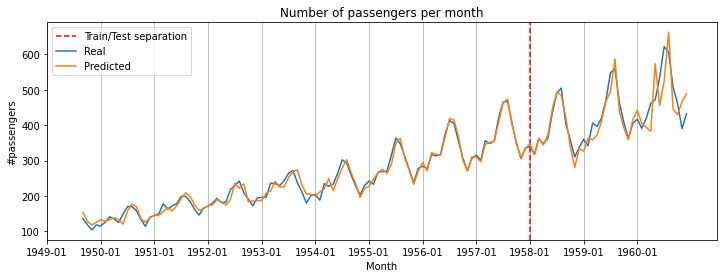

In [9]:
import matplotlib.pyplot as plt

lstm.eval()
train_predict = lstm(x)
labels_to_display = [i for i in range(training_data.shape[0]) if i % 12 == 0]
time_series_plot(train_predict)

### Выводы

---
1. Использование LSTM слоев при прогнозировании нестационарных временных рядов - отличное решение, т.к. нейронная сеть способна самостоятельно выделить динамики изменениях составляющих временного ряда. Правда, в более сложных случаях (трейдинге, например, или чтении и расшифровки волн мозга) приходится прибегать к feature engineering
2. Сложность нейронной сети должна быть адекватна сложности подаваемых в нее данных. С ростом ансамбля и числа нейронов увеличивается заучивание тренировочной выборки и теряется способность к обобщению
3. Предварительный анализ цикличности в данных (если она есть) помогает понять оптимальный размер ансамбля (тут видно, что цикл, в среднем, составляет 8 интервалов)
4. Также результат может зависеть от типа скалирования, который Вы применяете. Нужно знать принципы работы скаллеров. См. статьи: [Data Preprocessing with Scikit-Learn: Standardization and Scaling](https://towardsdatascience.com/data-preprocessing-with-scikit-learn-standardization-and-scaling-cfb695280412) и [Gradient Descent, the Learning Rate, and the importance of Feature Scaling](https://towardsdatascience.com/gradient-descent-the-learning-rate-and-the-importance-of-feature-scaling-6c0b416596e1)
5. При всей выгодности применения нейронных сетей, необходимо быть осторожным с автокорреляцией (см статью [Avoiding the pitfalls](https://towardsdatascience.com/how-not-to-use-machine-learning-for-time-series-forecasting-avoiding-the-pitfalls-19f9d7adf424))

### Модификации LSTM 

Было предложено множество модификаций структуры LSTM.

### Peephole connections
Например, введение возможности всем gates напрямую подсматривать в вектор контекста $C$. Что, безусловно, логично - сложно решать, что делать с вектором $C$ (что из него стирать, что в него добавлять, что из него брать), если видишь его только опосредованно. 

<img src="https://edunet.kea.su/repo/EduNet-content/L08/out/lstm_peepholes_connections.png" width="600px">

### Объединение forget и input gates 

Также, кажется, что правильно требовать от нейронной сети принимать решение о записи в/стирании из вектора $C$ одновременно. Если что-то стираем - надо что-то записать. И наоборот. 

<img src="https://edunet.kea.su/repo/EduNet-content/L08/out/lstm_join_input_and_forget_gate.png" width="600px">

### GRU (Gated reccurent unit)

Самая известная модификация LSTM - GRU. Она более компактна за счет сильных упрощений в сравнении со стандартной LSTM.

Главные изменения - объединены forget и input gates, слиты $h_t$ и $C_t$, которые в обычной LSTM только участвовали в формировании друг друга.

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/gru_basic_block.png" width="700">

In [10]:
gru = torch.nn.GRU(input_size=4, hidden_size=3)
input = torch.randn(2, 1, 4) #seq_len, batch, input_size
h0 = torch.randn(1, 1, 3)
output, h = gru(input, h0)

print("Input shape:".ljust(15), input.shape)
print("Shape of h:".ljust(15), h.shape) # last h
print("Output shape:".ljust(15), output.shape) # seq_len = 2

Input shape:    torch.Size([2, 1, 4])
Shape of h:     torch.Size([1, 1, 3])
Output shape:   torch.Size([2, 1, 3])


Практический опыт исследователей - иногда лучше работает GRU, иногда &mdash; LSTM. Точного рецепта успеха сказать нельзя

### Sequence-to-Sequence with RNNs

Попробуем решить задачу **sequence-to-sequence**: преобразование последовательности длины $N$ в последовательность длины $T$. $T$ может быть не равно $N$.

Примеры **sequence-to-sequence** задач:
*   машинный перевод,
*   генерация ответа на вопрос,
*   генерация описания картинки или видео.

Для решения таких задач  можно использовать две **RNN**: **кодировщик** и **декодировщик**. 
* Задача **кодировщика**: обобщить информацию о **входной последовательности** $(x_1,..., x_N)$, сформировав **вектор контекста** $C$ фиксированного размера.
* Задача **декодировщик**: используя информацию из $C$, сформировать **выходную последовательность** $(y_1, ..., y_T)$.

В качестве вектора $C$ можно использовать последнее **скрытое состояние** кодировщика $h_N$.

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/seq_to_seq_with_rnn.png" width="800">

В данном подходе мы используем один **вектор контекста** фиксированной длины $c$, в который собираем информацию со всей **входной последовательности** $(x_1,...,x_N)$.

**Входная последовательность** может содержать как единицы, так и тысячи элементов. В задаче машинного перевода **входной последовательностью** может быть:
* короткая фраза,
* абзац “Войны и мира”.

Контекст важен. Для генерации глагола в правильной форме, нужно понимать к какому существительному он относится, а для качественного перевода конца абзаца необходимо понимать, о чем шла речь в его начале. 

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/seq_to_seq_with_rnn.png" width="800">

При этом возникают проблемы:
- **Вектор контекста** $c$ фиксированной длины не может вместить любое количество информации, поэтому для длинных последовательностей качество будет ухудшаться. 
- На каждой итерации декодировщика **скрытое состояние** $s_t$ должно сохранять информацию о том, какие элементы **выходной последовательности** уже были сгенерированы. Если $s_t$ не способно вместить эту информацию модель может зациклиться или потерять часть **выходной последовательности**.

**Вектор контекста** $c$ и **скрытые состояния** декодировщика $s_t$ являются “бутылочными горлышками” модели.

Как решить проблему “бутылочного горлышка”?
* формировать свой контекст $c_t$ для каждого элемента **выходной последовательности** $y_t$,  
* использовать для формирования контекста $c_t$ все **скрытые состояния** кодировщика $h_i$.

### Sequence-to-Sequence with RNNs and Attention mechanism

Для формирования **векторов контекста** $(c_1, ..., c_T)$ возьмем линейную комбинацию **скрытых состояний** кодировщика $h_i$ с весами $a_{ti}$:
<center>$ c_t=\sum_{i=1}^{N}a_{ti}h_i$.</center>

Веса $a_{ti}$ указывают, какие **скрытые состояния** кодировщика $h_i$ важны для формирования элемента **выходной последовательности** $y_t$.  Они “показывают” декодировщику куда “смотреть” при генерации данного элемента. Такой механизм в нейросетях получил название **attention** (внимание).

Веса $a_{ti}$ предсказывает сама модель. Для удобства веса подбираются таким образом, чтобы их сумма для каждого **вектора контекста** $c_t$ была равна 1 (нормализация):
<center>$ \sum_{i=1}^{N}a_{ti} = 1$,</center>

<center>$  0\leqslant a_{ti} \leqslant 1$.</center>

Для этого на выходе предсказывающего веса слоя ставят **SoftMax**.

Чтобы **вектор контекста** $c_t$ содержал информацию о уже сгенеренных элементах **выходной последовательности**, значение веса до нормализации  $e_{ti}$ зависит не только от скрытого состояния кодировщика $h_i$, но и от предыдущего скрытого состояния декодировщика $s_{t-1}$.

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/seq_to_seq_with_rnn_and_attention_mechanism_step_1.png" width="1000">

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/seq_to_seq_with_rnn_and_attention_mechanism_step_2.png" width="1000">

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/seq_to_seq_with_rnn_and_attention_mechanism_step_3.png" width="700">

[Stanford University CS231n: Recurrent Neural Networks](http://cs231n.stanford.edu/slides/2017/cs231n_2017_lecture10.pdf)

Давайте посмотрим, как такой подход  работает на примере перевода с английского на французский 

Как мы знаем, на каждом шаге генерируется набор весов, которые отвечают за фокусировку на том или ином месте входной последовательности. Как мы видим, английское предложение имеет иной порядок слов относительно французского. Например, в английском варианте словосочетание **European Economic Area**, в то время как во французском **zone économique européenne**. 

В английском прилагательные идут перед существительным, в то время как во французском языке наоборот. 

Таким образом, благодаря гибкости модели, мы можем обрабатывать и учитывать разный порядок слов в разных языках.

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/visualize_attention_weights.png" width="700">

* Механизм внимания не обязательно должен принимать на вход последовательность. 

* Мы можем применять его, в том числе для генерации подписей для картинок. Входом в данном случае будет являться матрица признаков, которая была получена при применении сверточной сети к картинке. 

* Далее по этой матрице мы считаем веса внимания и делаем аналогично первому примеру.

Следующим шагом будет также заметить, что для достаточно длинного предложения наша модель может забыть и то, что она генерирует. Потому мы можем сделать два attention - один на представление исходного предложения, а второе - на представление того, что уже сгенерировано (что еще не сгенерировано - заменяем нулями)

### Проблема attention

Очевидно, у этого подхода есть свои минусы. 

Самый важный из них - ваша модель должна уметь предсказывать веса, с которыми складываются слова из предложения при формировании нового контекстного вектора $c$. И обычные подходы принуждают нас фиксировать размер этого вектора весов. 

За счет этого у нас возникает ограничение, от которого мы избавлялись - модель не может принимать (и, если используем attention на то, что сгенерировано, генерировать) предложения больше определенного размера. С другой стороны, ничто не мешает поставить этот максимальный размер достаточно большим, чтобы для бОльшей части предложений это работало. 

Почему это не сильный проигрыш в сравнении с LSTM - так оно все равно было ограничено в длине предложения, просто неявно, что даже хуже - лучше иметь модель, которая на длине предложения 45 падает, а не генерирует лабуду. 

### Image Captioning with RNNs and Attention

Модели, основанные на внимании (attention) намного более продвинутые, нежели обычные нейронные сети. Они могут концентрироваться на отдельных частях данных, что позволяет избежать зашумления представлений.

Идея состоит в том, что на каждом этапе генерации описания, нейронная сеть в разной степени обращает внимание на те или иные фрагменты изображения, соответствующие следующему слову в описании.

После обучения модели можно увидеть, что она как бы переносит свое внимание по изображению для каждого генерируемого слова.

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/image_captioning_with_rnn_and_attention_example_step_1.png" width="700">

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/image_captioning_with_rnn_and_attention_example_step_2.png" width="700">

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/image_captioning_with_rnn_and_attention_example_step_3.png" width="700">

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/image_captioning_with_rnn_and_attention_example_step_4.png" width="700">

[Stanford University CS231n: lectures](http://cs231n.stanford.edu/slides/2017/)

Посмотрим, что “привлекает внимание” нейронной сети при написании текстового описания картинки. 

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/visulize_attention_map.png" width="700">

Нейронные сети, использующие механизм внимания (attention) активно применяются для решения задачи [Visual Question Answering](https://paperswithcode.com/paper/vqa-visual-question-answering). В данной задаче нейросеть должна научиться давать развернутые ответы на вопросы по изображению. Модель должна не только решать задачу классификации, но и распознавать признаки (цвет, форма, размер, количество и т.д.) предметов на изображении, различать в какой части изображения находится предмет и его положение относительно других предметов. Решение этой задачи может помочь людям с проблемами со зрением лучше ориентироваться в пространстве. 

[ссылка на исследование](https://www.reg.ru/blog/nejroset-opisyvaet-mir-nezryachim-lyudyam/) 
и еще [одна ссылка](https://www.reg.ru/blog/uchim-nejroseti-rassuzhdat-o-tom-chto-oni-vidyat/)

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/visulize_attention_map_examples.png" width="700">

### Key, query, value 

Мы можем формализовать процедуру attention через введение концепций **key**, **query** и **value**. 

К примеру, у нас есть картинка. На этой картинки у нас есть области, которые можно описать одним словом - **key**. Например - фонарь/девушка/... 

Сами эти области - это **value**, которые введенным **key** соответствуют. 

Далее нам приходит **query** - например, running. Мы можем посчитать похожесть каждого из ключей, которые у нас есть на query. 

И далее выдать информацию только по **value**, похожим на наш **query**.

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/key_query_value_example.jpg" width="800">

[Послезная статья про NLP — BERT & Transformer, откуда взяты картинки по теме](https://jonathan-hui.medium.com/nlp-bert-transformer-7f0ac397f524)

По сути, мы описали то, как будем делать при помощи нейронок питоновский словарь. С той разницей, что питоновский словарь может выдавать значения только для тех ключей, что в нем есть, а наш словарь выдает ответ для любого ключа-запроса, основываясь на его похожести на ключи словаря

### Key, Query, Value на примере текста 

Разобьем наше предложение на токены (в данном случае - просто слова). Получим представление каждого токена

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/key_query_value_sentence.png" width="800">

Каждое слово будет являться одновременно и key, и value. 

Теперь можно подать любой query, например - вода, и в случае, если у нас эмбединги слов хорошие, что нам "подсветятся" слова, связанные с водой.

### Attention Layer

Эту идею реализует attention layer. 

Что мы, таким образом, получили? Фактически, мы получили дифференцируемый аналог словаря в Python. Только этот словарь еще умеет делать неточный поиск

У нас есть некий изначальный набор $X$ - слова в нашем предложении. 

Мы можем их преобразовать как-то, чтобы получить более удобные для дальнейшей цели $K$ - предполагается, что они лучше помогают сравнивать между собой слова. 
В простейшем случае некое линейное преобразование $K = XW_K$

Далее у нас есть значения, $V$, которые тоже получаются из $X$ путем какого-то преобразования, которое делает их более применимыми для работы модели (важные признаки и тд), например $V = XW_Q$

Далее к нам приходят запросы $Q$, которые находятся в том же пространстве, что и ключи. Фактически - наша нейросеть пытается вытащить из данных интересующую ее информацию. К примеру - ей нужно найти всех животных и все растения - тогда $Q = \text{\{“животные”, “растения”\}}$

Мы сравниваем эти запросы с ключами - считаем просто попарные косинусные расстояние между каждым ключом $K_i$ и запросом $Q_j$. Получаем похожесть каждого ключа на запрос, нормируем ее на корень из размерности представления нашего ключа. 

$E = \dfrac {QK^T} {\sqrt{D}} $

Получили матрицу похожестей $E$, где $E_{ij}$ - похожесть ключа $K_i$ на запрос $Q_j$

Далее мы применяем к похожестям $E$ softmax, беря его по каждому ключу отдельно (по каждому столбцу матрицы $E$). Теперь у нас похожести каждого запроса складываются в единицу. 

$A = softmax(E,\, dim=1)$

Получили для каждого запроса его "разложение" в виде ключей. 

Далее, чтобы получить значения, соответствующие каждому запросу, складываем значения с весами соответствующих ключей

$\displaystyle Y_j = \sum_iA_i V_i$

$Y = AV$

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/attention_layer.png" width="800">

### Softmax normalization 

Вы могли заметить, что в формуле для $E$ мы делим на корень из размерности представления ключа. Зачем это?

Давайте сгенерируем вектор из многомерного нормального распределения

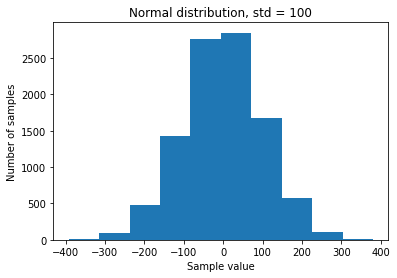

In [11]:
import numpy as np 
import matplotlib.pyplot as plt 

a = np.random.normal(0, 100, size=(10000))

plt.title("Normal distribution, std = 100")
plt.ylabel("Number of samples")
plt.xlabel("Sample value")

plt.hist(a)
plt.show()

И посмотрим, что будет с распределением значений этого вектора, если к нему применить softmax

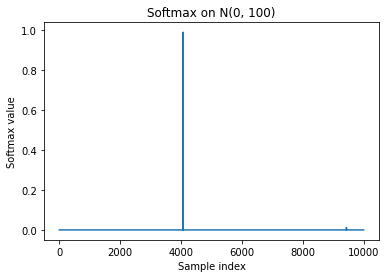

In [12]:
from scipy.special import softmax 

plt.title("Softmax on N(0, 100)")
plt.ylabel("Softmax value")
plt.xlabel("Sample index")

plt.plot(softmax(a))
plt.show()

Почти все значения 0 и одно (наибольшее), стало 1. 
Мы получили так называемое вырожденное распределение - у него вся плотность сосредоточена в одной точке. 

И получили на абсолютно случайных данных. 

Это приведет к затуханию градиента - мы будем распространять ошибку только для 1 значения из 10000. Учиться сеть будет плохо

Но этого можно избежать - давайте просто стандартизируем наши данные 

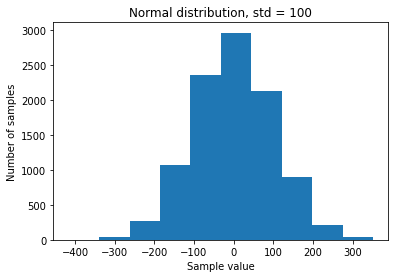

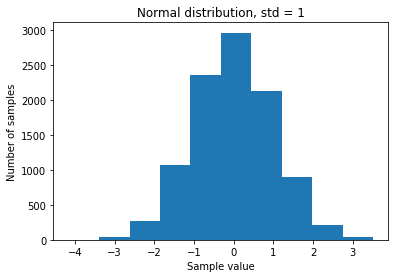

In [13]:
std = np.random.normal(0, 100, size=(10000))

unit_std = std / 100

plt.title("Normal distribution, std = 100")
plt.ylabel("Number of samples")
plt.xlabel("Sample value")
plt.hist(std)
plt.show()

plt.title("Normal distribution, std = 1")
plt.ylabel("Number of samples")
plt.xlabel("Sample value")
plt.hist(unit_std)
plt.show()

По сути, в распределении ничего не поменялось - только масштаб. Но теперь softmax работает нормально 

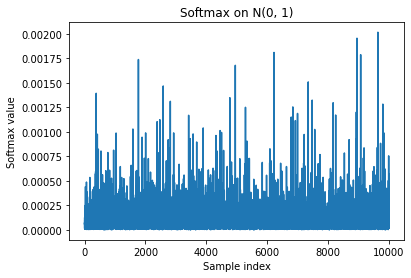

In [14]:
plt.title("Softmax on N(0, 1)")
plt.ylabel("Softmax value")
plt.xlabel("Sample index")

plt.plot(softmax(unit_std))
plt.show()

Остается только понять, а как нормировать наши данные в нашем слое? Считать налету, наверное, не лучшая идея. 

Наш слой делает скалярное произведение между двумя векторами, предположим, нормально распределенными

In [15]:
def statistics(dimensionality, experiments=int(10e4)):
    c = []
    for i in range(experiments):
          a = torch.normal(0, 1, size=(int(dimensionality),))
          b = torch.normal(0, 1, size=(int(dimensionality),))
          c.append(torch.dot(a, b))
        
    c = torch.Tensor(c)
    return float(c.mean()), float(c.std())

In [16]:
import torch

means, stds = {}, {}
dims = torch.linspace(0, 100, 20)

for dim in dims:
		dim = float(dim)
		t_mean, t_std = statistics(dim)
		means[dim] = t_mean
		stds[dim] = t_std

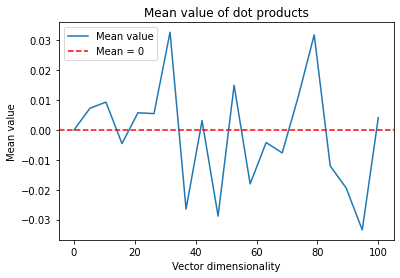

In [17]:
x = list(means.keys())
y = list(means.values())

plt.plot(x, y)
plt.axhline(y=0, c='r', linestyle='--')
plt.legend(['Mean value', 'Mean = 0'])
plt.title("Mean value of dot products")
plt.ylabel("Mean value")
plt.xlabel("Vector dimensionality")
plt.show()

Видим, что среднее не сильно отличается от 0 (можно показать, что в среднем оно равно 0 для произведения нормально распределенных величин). 

А вот стандартное отклонение растет. И, можно предположить, что растет оно как корень из размерности вектора. Так и есть. Потому и появляется именно такой нормировочный множитель в attention

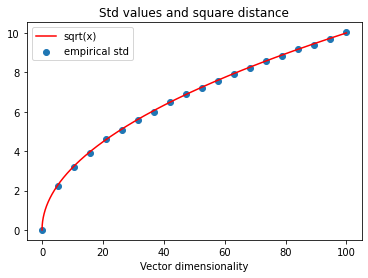

In [18]:
x = list(stds.keys())
y = list(stds.values())
plt.scatter(x, y)
plt.title("Std values and square distance")
plt.xlabel("Vector dimensionality")

x = np.linspace(0, 100, 10000)
plt.plot(x, x**0.5, color='r')
plt.legend(["sqrt(x)", "empirical std"])
plt.show()

### Keq, Query, Value на примере текста. Второй заход

Хорошо, у нас есть предложение, мы его разбили на токены, допустим, мы хорошо умеем кодировать эти токены. 

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/key_query_value_sentence.png" width="800">

Но каждый токен закодирован на основе самого себя, и только, например, слово bank встречается в тексте два раза, и будет закодировано одинаково, хотя несет разные значения (берег и, собственно, банк). 

Как нейросети их отличать? Ну, если мы попытаемся на основе только одного токена что-то сделать - никак. 

А как улучшить кодирование каждого токена, чтобы два "банка" отличались? 

Сделаем следующее - каждый токен подадим в нейросеть **и в качестве query**. 

И будем агрегировать полученную информацию, получая токен, который будет содержать более конкретную информацию

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/key_query_value_sentence_example.png" width="800">

Например, bank, который банк, будет содержать информацию о том, что он не просто bank, а "Bank of America", который нужно найти (find).

Такой подход - когда key, query и value формируются на основе одного и того же входа нейросети называется self-attention

### Self-Attention Layer

Сделаем это все в виде слоя

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/self_attention_layer.png" width="800">

Что изменилось? 

Теперь $X$ участвует и в производстве $K$, и в производстве $V$, и в производстве $Q$. Потому и self-attention - предложение состоящее из слов $X_i$, ищет само себя в нашем дифференцируемом словаре. Почему это не приводит к тому, что мы просто получим вектор $V$?
Потому что значения $X_i$ модифицируются и $K \neq Q$.

Еще один пример проблемы с текстом, который обычные методы решали плохо

Многие из нас знают Второй Закон Робототехники

**Second Law of Robotics**


A robot must obey the orders given it by human beings except where such orders would conflict with the First Law.

Представим, что машина хочет понять, что здесь написано. И ей нужно понять, что имеется ввиду под it. 

Первым делом она формирует на основе каждого слова key и value. 

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/self_attention_example_folders_step_1.png" width="800">

Затем она смотрит, какие ключи похожи на Query, полученный из it

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/self_attention_example_folders_step_2.png" width="800">

Чтобы получить, что же на самом деле значит it, машина считает взвешенную сумму values, где  веса определяются похожестью query на value

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/gpt2_value_vector_sum.png" width="800">

[Ссылка на оригинальную статью про GPT-2 с более подробными объяснениями как оно работает.](https://jalammar.github.io/illustrated-gpt2/)

В итоге получается, что it представляет собой "a robot" (ну и само себя). 

Ниже приведена простая реализация слоя self-attention.

In [19]:
import torch.nn as nn

class SimplifiedSelfAttention(nn.Module): 
    def __init__(self, input_size, key_size=100, value_size=20):
        super().__init__()
        self.keyer = nn.Linear(input_size, key_size)
        self.valuer = nn.Linear(input_size, value_size)
        self.querier = nn.Linear(input_size, key_size)

        self.norm_factor = key_size ** 0.5

    def forward(self, x):
        print("Input shape:".ljust(20), x.shape)

        query = self.querier(x)
        key = self.keyer(x)
        value = self.valuer(x)

        print("Query shape:".ljust(20), query.shape)
        print("Key shape:".ljust(20), key.shape)
        print("Value shape:".ljust(20), value.shape)

        activations = torch.mm(query, key.t()) / self.norm_factor
        norm_activation = nn.functional.softmax(activations, dim=1)
        result = torch.mm(norm_activation, value)

        print("Activations shape:".ljust(20), activations.shape)
        print("Result shape:".ljust(20), result.shape)

        return result

In [20]:
in_size = 30
data = torch.randn(10, in_size)

SA = SimplifiedSelfAttention(in_size)
result = SA(data)

Input shape:         torch.Size([10, 30])
Query shape:         torch.Size([10, 100])
Key shape:           torch.Size([10, 100])
Value shape:         torch.Size([10, 20])
Activations shape:   torch.Size([10, 10])
Result shape:        torch.Size([10, 20])


### Positional encoding

Единственный возможный минус - наша нейронная сеть не учитывает порядка слов в предложении при составлении embedding. Это может нам мешать. Например, если в предложении два it, то они часто относятся к разным словам. Потому хотим уметь учитывать информацию о позиции. Для этого к $X$ при составлении $Q$ добавляется информация о позиции. 

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/positional_encoding.png" width="700">

Делается это хитрым образом - мы берем и добавляем к каждому значению исходного вектора токенов некую комбинацию $sin$ и $cos$ с разными параметрами. 

Вектор $PE$, который мы будем добавлять к $X$ будет определяться по следующей формуле

$$PE_{pos, 2i} = \sin \left({\dfrac {pos} {10000^{2i/d}}}\right)$$

$$PE_{pos, 2i+1} = \cos \left({\dfrac {pos} {10000^{2i/d}}}\right)$$

$pos$ &mdash; это позиция токена

$d$ &mdash; количество размерностей токена

$i$ &mdash; $i$-тая размерность токена

In [21]:
import math

class PositionalEncoding(nn.Module):
    "Implement the PE function."
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()
        
        # Compute the positional encodings once in log space.
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2) *
                             -(math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer('pe', pe)
        
    def forward(self, x):
        x = x + self.pe[:, :x.size(1)].detach() 
        return x

In [22]:
pe = PositionalEncoding(20)
y = pe(torch.zeros(1, 100, 20)) # sequence of shape 100, every token of sequence has shape 20  

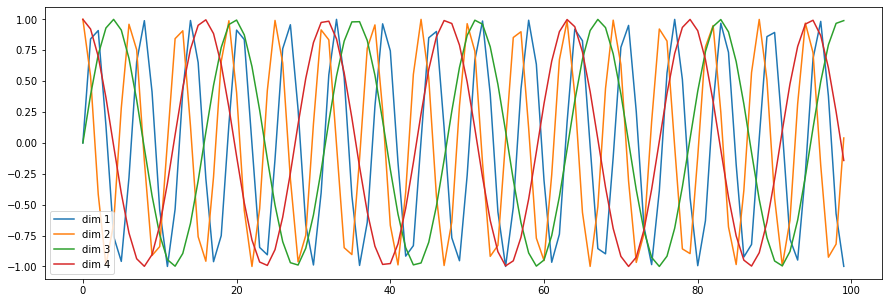

In [23]:
plt.figure(figsize=(15, 5))
plt.plot(np.arange(100), y[0, :, 0:4].data.numpy())
plt.legend(["dim %d"%p for p in [1,2,3,4]])
plt.show()

В результате каждая позиция коддируется уникальным представлением. При этом представление позволяет легко находить слова на заданном расстоянии от исходного (у них будет одинаково значение сигнала по какой-то оси)

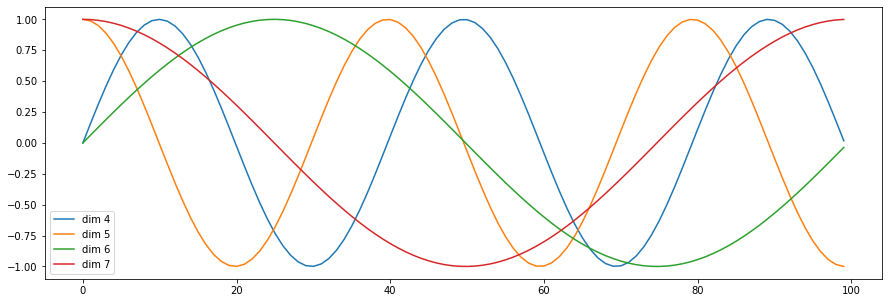

In [24]:
plt.figure(figsize=(15, 5))
plt.plot(np.arange(100), y[0, :, 4:8].data.numpy())
plt.legend(["dim %d"%p for p in [4, 5, 6, 7]])
plt.show()

Это помогает трансформеру достаточно уникальным образом определять каждую позицию и понимать относительное расстояние между разными токенами

### Masked Self-Attention Layer

Допустим,  у нас стоит проблема, что мы не должны видеть часть слов в предложении - например, при генерации текста (по текущим словам предсказать следующее). Например, хотим сгенерировать фразу "robot must obey orders" на основе только первого слова. 

Если мы скормим в нейронную сеть во время обучения сразу все предложение, которое хотим генерировать, то у нас в первых словах будет "протекать" информация о предыдущих.

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/queries_keys_scores_before_softmax.png" width="800">

В этом случае мы можем просто на соответствующих местах матрицы $E$ поставить минус бесконечности - тогда в эмбедингах слов, которые не должны знать о каких-то словах, информации об этих словах не будет.

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/scores_before_softmax_apply_attention_mask_masked_scores_before_softmax.png" width="800">

В результате мы сможем, после softmax "лишняя" информация не будет использоваться при генерации ответа на query

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/masked_scores_softmax_along_rows_scores.png" width="800">

Благодаря этому трюку, у нас получается обучать transfomer по-прежнему как простую single-pass нейронная сеть, а не "скатываться" в RNN, где у нас возникнут проблемы с градиентами и временем работы 

### Multihead Self-Attention Layer

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/multihead_self_attention_layer.png" width="700">

Давайте посмотрим на то, к каким словам предложения gave может иметь отношение. В общем случае глагол может иметь связку со многими частями предложения. Как, например, с подлежащим, так и с причастиями.

В идеале, нам бы хотелось обратить внимание функции (attention) на все эти взаимосвязи. Для этого нам просто надо поставить несколько attention слоев параллельно. В идеале каждый будет учить что-нибудь свое - аналогия с конволюциями. 

* Чтобы осуществить задуманное, вместо одного набора query, будем использовать несколько независимых наборов. 

* Причем каждый набор будет считаться уникальной матрицей. 

* Аналогично сделаем для keys и values. Количество таких наборов внутри keys, queries, values должно быть **одинаковым**. 

* Обозначим это число как h - head, далее производим аналогичные манипуляции, при этом введем в параллель h таких функций attention
* На последнем шаге мы их соединяем (конкатинируем)

* При этом можно заметить, что таком подходе на каждом шаге размерность токена будет увеличиваться (если, например, в качестве и key, и value, и query мы подаем одно и тоже предсталение токена). Если хотим сохранять управлять размерностью токена, то придется получать, по меньшей, мере value путем домножения на матрицу, размерность которой по второй оси меньше - **выполнять проекцию наших токенов в пространство меньшей размерности**

* В частности, можно подобрать размерность этого пространства таким образом, чтобы при конкатенации размерность полученного токена равнялась исходной. 

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/scaled_dor_product_attention_multihead.png" width="900">

### Attention is all you need

Оказывается, этот подход работает сам по себе. Не нужно добавлять никаких рекуррентных слоев - просто делаем много правильно соединенных attention layers. Полученная в результате архитектура получала название attention transformer

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/attention_is_all_you_need.png" width="800">

### Базовый блок 

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/attention_transformer_basic_block.png" width="700">

Блок устроен следующим образом: входные вектора мы запускаем в блок self-attention и используем residual connection как обходной путь вокруг self-attention, затем мы их складываем. Так как обычно используют multi head self-attention, тут нам и пригождается возможность подобрать параметры так, чтобы размерности входных и выходных токенов не отличались. 

После - применяем слой нормализации, затем - слой feed forward (MLP), плюс обходной путь вокруг feed forward.

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/mlp_transformer_block.png" width="900">

Складываем выход MLP-части с residual connection и выполняем нормализацию.

Нормализация везде нужна для того, чтобы нейросеть нормально обучалась. 

Заводим ли разный MLP на каждый токен (по позиции) - конечно нет. К каждому токену применяются MLP с одними и теми же весами.

В реальных моделях выходы этих слоев стекают друг с другом и получается большая трансформер-модель. 

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/mlp_transformer.png" width="600">

Это пример Encoder-модели. Такова рассматриваемая далее BERT. В такой модели на выходе мы получаем некое хорошее представление исходного предложения. 

Но что если мы хотим сделать задачу перевода с одного языка на другой? Нужен еще Decoder

### Decoder 

### Первая стадия

На первой стадии то, как работает Decoder не так сильно отличается от работы Encoder. 

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/decoder_transformer.jpg" width="800">

Тем не менее, есть один важный нюанс -  мы используем Masked Attention - наша нейросеть не должна видеть слов, которые еще не сгенерировала. 

На основе первого этапа у нас формируются только query - наша нейросеть на основе того, что она уже сгенерировала решает, какая информация ей нужна дальше 

### Вторая стадия

Теперь мы используем для $K$, $V$ информацию, полученную из энкодера и получаем предсказание.

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/encoder_decoder_transformer.jpg" width="800">

### Токенизация

Перед тем как перейти к самым ярким примерам использования трансформеров, давайте разберёмся, как именно трансформеры взаимодействуют с текстом. Мы же не можем загрузить буквы, слова и предложения в нейронную сеть. Нам необходимо загружать вектора. Выше по тексту (для посимвольной генерации), эту проблему мы решали следующим образом: создавали *словарь* для букв и каждой букве присваивали индекс (a=0, b=1, c=2 ...). Давайте посмотрим, можем ли мы провернуть то же самое для предложений.

### Наивная токенизация

Рассмотрим предложение: `Я люблю Natural Language Processing (NLP). А ты?`
 
Присваивать отдельный индекс каждому предложению, кажется, совсем не оптимально. Что тогда? Мы можем разбить предложение на слова (*токенезировать предложение*) по пробелам.

In [25]:
input = 'Я люблю Natural Language Processing (NLP). А ты?'
tokenized = input.split(' ')
print(tokenized)

['Я', 'люблю', 'Natural', 'Language', 'Processing', '(NLP).', 'А', 'ты?']


Неплохо, но можно обратить внимание, что мы не учли пунктуацию. Кажется неразумным создавать отдельный индекс для каждой комбинации NLP и знаков препинания. Давайте проведём токенизацию с учётом знаков препинания

In [26]:
import re
  
# initializing string
input = 'Я люблю Natural Language Processing (NLP). А ты?'
  
# using findall() to get all regex matches. 
res = re.findall(r'\w+|[^\s\w]+', input)
  
# printing result 
print(str(res)) 

['Я', 'люблю', 'Natural', 'Language', 'Processing', '(', 'NLP', ').', 'А', 'ты', '?']


Лучше, но представьте себе размер словаря, если мы будем токенизировать таким образом все слова в Википедии. Такой большой объём словаря приведёт к тому, что у модели будет огромный размер эмбедингов в качестве входного и выходного слоя, что приведёт к увеличению необходимой памяти. Обычно, размер словаря трансформеров не превышает 50 000 токенов. Почему бы тогда не использовать посимвольную токенезацию, как раньше?

Хотя посимвольная токенизация очень проста и значительно снижает требования к памяти, она значительно усложняет обучение модели осмысленным представлениям входных данных. Например, выучить осмысленное контекстно-независимое представление для буквы `"с"` гораздо сложнее, чем выучить контекстно-независимое представление для слова `"сегодня"`. Поэтому токенизация символов часто сопровождается потерей производительности. Чтобы получить лучшее из двух миров, трансформеры используют что-то среднее между токенизацией на уровне слов и на уровне символов, называемый токенизацией подслова (*subword tokenization*).

### *Subword Tokenization* (Токенизация подслова)

Алгоритмы токенизации подслова основываются на принципе, что часто используемые слова не должны разбиваться на более мелкие подслова, а редкие слова должны быть разложены на значимые подслова. Например, слово "*annoyingly*" может считаться редким словом и может быть разложено на "*annoying*" и "*ly*". И "*annoying*", и "*ly*" как самостоятельные подслова будут встречаться чаще, и в то же время значение слова "*annoyingly*" сохранится за счёт составного значения "*annoying*" и "*ly*".
 
Токенизация подслова позволяет модели иметь разумный объём словаря и при этом обучаться значимым контекстно-независимым представлениям. Кроме того, токенизация подслова позволяет модели обрабатывать слова, которые она никогда раньше не видела, путём разложения их на известные подслова.

Воспользуемся популярной библиотекой для токенизации от команды Hugging Face `transformers`

In [27]:
!pip -q install transformers

     |████████████████████████████████| 5.5 MB 6.8 MB/s 
     |████████████████████████████████| 163 kB 66.3 MB/s 
     |████████████████████████████████| 7.6 MB 45.0 MB/s 


In [28]:
from transformers import BertTokenizer

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
tokenizer.tokenize("I have a new GPU!")

Downloading:   0%|          | 0.00/232k [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/570 [00:00<?, ?B/s]

['i', 'have', 'a', 'new', 'gp', '##u', '!']

Предложение сначала было приведено к нижнему регистру. Мы видим, что слова ["i", "have", "a", "new"] присутствуют в словаре токенизатора, а слово "gpu" - нет. Следовательно, токенизатор разбивает "gpu" на известные подслова: ["gp" и "##u"]. "##" означает, что остальная часть лексемы должна быть присоединена к предыдущей без пробела (для декодирования или обратного хода токенизации).

### Byte-Pair Encoding (BPE)

Кодирование байт-парой (BPE) опирается на претокенизатор, который разбивает обучающие данные на слова. Примером простой претокенизации может быть разбивка по пробелам. Более продвинутая предварительная токенизация включает токенизацию на основе каких-то правил.

После предварительной токинизации у нас получится набор уникальных слов и будет определена частота встречаемости каждого слова в обучающих данных. Затем BPE создаёт базовый словарь, состоящий из всех символов, которые встречаются в наборе уникальных слов, и изучает правила слияния для формирования нового символа из двух символов базового словаря. Так происходит до тех пор, пока словарный запас не достигнет желаемого размера. Обратите внимание, что желаемый объём словаря - это гиперпараметр, который необходимо определить перед обучением токенизатора.

В качестве примера предположим, что после предварительной токенизации был определён следующий набор слов, включая их частоту:

`("hug", 10), ("pug", 5), ("pun", 12), ("bun", 4), ("hugs", 5)`

Видим, что базовый словарь -  `["b", "g", "h", "n", "p", "s", "u"]`. 

Разделим все слова на отдельные буквы: 

`("h" "u" "g", 10), ("p" "u" "g", 5), ("p" "u" "n", 12), ("b" "u" "n", 4), ("h" "u" "g" "s", 5)`

BPE подсчитывает частоту каждой возможной пары символов и выбирает ту пару символов, которая встречается наиболее часто. В приведённом выше примере `"h"`, за которым следует `"u"`, встречается 10 + 5 = 15 раз (10 раз в 10 вхождениях слова `"hug"`, 5 раз в 5 вхождениях слова `"hugs"`). Однако наиболее частой парой символов является `"u"`, за которой следует `"g"`, встречающаяся 10 + 5 + 5 = 20 раз в общей сложности. Таким образом, первое правило слияния, которому обучается токенизатор, - это сгруппировать все символы `"u"`, за которыми следует символ `"g"`, вместе. Затем `"ug"` добавляется в словарный запас. После этого набор слов становится следующим:

`("h" "ug", 10), ("p" "ug", 5), ("p" "u" "n", 12), ("b" "u" "n", 4), ("h" "ug" "s", 5)`

Затем BPE определяет следующую наиболее часто встречающуюся пару символов. Это `"u"`, за которым следует `"n"`, который встречается 16 раз. `"u"`, `"n"` объединяются в `"un"` и добавляются в словарь. Следующая по частоте пара символов - `"h"`, за которой следует `"ug"`, встречается 15 раз. Снова пара объединяется, и `"hug"` может быть добавлен в словарь.

На данном этапе словарный запас состоит из `["b", "g", "h", "n", "p", "s", "u", "ug", "un", "hug"]`, а наш набор уникальных слов представлен как

`("hug", 10), ("p" "ug", 5), ("p" "un", 12), ("b" "un", 4), ("hug" "s", 5)`

Если остановить обучение BPE на этом моменте, то выученные правила слияния будут применяться к новым словам (при условии, что эти новые слова не содержат символов, которых не было в базовом словаре). 

Например, слово `"bug"` будет токенизировано как `["b", "ug"]`, а `"mug"` будет токенизировано как `["<unk>", "ug"]`, поскольку символ `"m"` отсутствует в базовом словаре. Как правило, отдельные буквы, такие как `"m"`, не заменяются символом `"<unk>"`, поскольку обучающие данные обычно включают хотя бы одно вхождение каждой буквы, но это может произойти для очень специальных символов, таких как эмодзи.

Как упоминалось ранее, размер словаря, т.е. размер базового словаря + количество слияний, является гиперпараметром для выбора.

Есть и множество других форм токенизации, подробнее о них можно прочитать в [Summary of the tokenizers](https://huggingface.co/docs/transformers/tokenizer_summary).

### Примеры применений Transformer

Непосредственное применение разобранной архитектуры Encoder-Decoder для перевода текста

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/transformer_text_translation_example.png" width="800">

[The Illustrated BERT, ELMo, and co. (How NLP Cracked Transfer Learning)](https://jalammar.github.io/illustrated-bert/)

### BERT (Bidirectional Encoder Representations from Transformers )

В случае BERT используется только Encoder часть

Это нейронная сеть, предобученная на огромном корпусе английского текста. 

Перед ней ставили следующие задачи:

**Задача 1**

На вход дается предложение - в нем выбрано $15\%$ токенов, из которых:  
1. $80\%$ замаскированы  
2. $10\%$ заменены случайным  
3. $10\%$ оставлены без изменений

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/bert.jpg" width="800">

$CLS$ токен нужен для того, чтобы нейросети было, куда класть информацию обо всем предложении в целом. 

$SEP$ нужен просто для того, чтобы разделять два предложения (если мы подаем их два) и для того, чтобы отмечать окончание. Использование $SEP$ с двумя целями позволяет подавать в уже обученную нейросеть только одно предложение. 

### Masked Language Model

Для первой задачи используем Encoder-Decoder 

То есть у нас есть **Encoder**, который получает богатые представления и добавленный только на время обучения **Decoder** (не attention, просто MLP).

Именно Decoder отвечает за то, чтобы предсказывать пропущенные/замененные токены. Ошибка считается только по тем $15\%$ токенов, для которых могло произойти изменения, а не по всему предложению.

Как гарантируется, что модель не заменяет имевшиеся в предложение слова на другие? 

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/masked_language_model.png" width="800">


### Next Sentence Prediction 

Для второй задачи - Classifier. 

При этом на вход ему подается только сам CLS токен 

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/next_sentence_prediction.png" width="800">

Обучаем модель на обеих задачах одновременно. 

### Transfer learning с BERT 

Обученную таким образом модель (оставляем только encoder), можно использовать для огромного числа других задач 

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/transfer_learning_with_bert.jpg" width="800">

### Zero-shot learning 

Более того, есть BERT, тренированная на большом числе разных языков.

Это позволяет, например, сравнивать предложения из разных языков, хотя мы этому даже не учились. Поиграть можно [здесь](https://colab.research.google.com/github/deepmipt/dp_tutorials/blob/master/Tutorial_2_DeepPavlov_BERT_transfer_learning.ipynb#scrollTo=S1iqGcxUINyU). Веса будут грузиться ДОЛГО

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/zero_shot_learning_bert.png" width="800">

### Специализированные аналоги BERT

Более того, можно тренировать BERT под строго определенные задачи - например, анализ текстов научных статей 

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/bert_specialized_analogs.png" width="800">

### GPT (Generative Pretrained Transformer )

В случае GPT используется только Decoder часть. Но теперь во всех частях используются masked attention 

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/generative_pretrained_transformer_gpt.png" width="800">

Это нейронная сеть обширно используется для, например, задачи генерации текста.

Работает она следующим образом - даем ей в качестве исходного входа какую-то затравку. 

Можно просто SOS (Start of sentence) токен, обозначающий начало предложения и больше не несущий никакой дополнительной информации


Она дает какой-то выход. Подаем этот выход нейросети как вход. 
Делаем так до тех пор, пока не надоест/не достигнем максимальной длины предложения/не встретим символ окончания генерации

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/gpt2_autoregression.gif" width="800">

Как ее обучали - на самом деле, тоже unsupervised. Но теперь перед моделью ставится задача предсказывать по предыдущим словам в предложении текущее.

Понятно, что такую модель можно сразу же идти и использовать для генерации, для которой она и училась 

Однако затем ее можно применять для многих других задач (опять же, путем transfer learning):


1. Классификации - подаем сразу все предложение, полученное представление используем для предсказания

2. Entailment (Определение логического следования) - даем изначальные данные, гипотезу, надо оценить, следует ли гипотеза из данных

3. Similarity - можем оценивать похожесть предложений. Так как это мы определяем порядок предложений, то, чтобы избежать неявной зависимости от порядка пропускания предложений, будем использовать результат пропускания через нейросеть обоих возможных порядков. 

4. Выбор варианта ответа на вопросы - может обучить нейросеть отвечать на вопросы с множественным выбором. 

<img src ="https://edunet.kea.su/repo/EduNet-content/L08/out/gpt_classification_entailment_similarity.png" width="1000">

Также можно научить нейросеть отвечать на вопросы и т.д. 

Строго говоря, мы можем даже текст переводить с помощью GPT. 

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/decoder_only_transformer_translation.png" width="800">

Просто подаем предложение с токеном в конце, определяющим, на какой язык переводим

По аналогичной схеме можем научить нашу сеть [делать summary текста](https://arxiv.org/abs/2109.10862)

<img src ="https://edunet.kea.su/repo/EduNet-web_dependencies/L08/decoder_only_summarization.png" width="800">

[Здесь](https://6b.eleuther.ai/) можно поиграть с open-source GPT-J

А [здесь](https://colab.research.google.com/github/kingoflolz/mesh-transformer-jax/blob/master/colab_demo.ipynb#scrollTo=e-NKauYvgTNG) - поиграть, но уже в Collab

<font size = "6">Хорошие источники 

[Про трансформеры](https://www.notion.so/Transformers-969f4b27c48147778c1e2dbda0c83ce0)

[Аннотированный трансформер](http://nlp.seas.harvard.edu/2018/04/03/attention.html)

[Код множества моделей с красивыми комментариями](https://nn.labml.ai/)

[BERT](https://medium.com/@samia.khalid/bert-explained-a-complete-guide-with-theory-and-tutorial-3ac9ebc8fa7c)

[Зоопарк BERT](https://ai.plainenglish.io/so-how-is-bert-different-ad43a42cab48)

[От NLP до Transformer](https://jonathan-hui.medium.com/nlp-bert-transformer-7f0ac397f524)

[Illustrated transformer](https://jalammar.github.io/illustrated-transformer/)

[Illustrated GPT-2](https://jalammar.github.io/illustrated-gpt2/)

[Open-source реализация GPT-3](https://arankomatsuzaki.wordpress.com/2021/06/04/gpt-j/)

[Transformer для русского языка](https://github.com/vlarine/transformers-ru)